# Tugas 1 Preprocessing Data

Dataset mahasiswa ini masih ada missing value, format tanggalnya belum sama, dan kolom kategorinya masih teks. Di bawah ini data dibersihkan dulu biar bisa dipakai training model.

## Tahap 1: Load Dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

df = pd.read_csv('dataset_tugas1_preprocessing.csv')
df.head()

,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
0,MH001,Iwan,Laki-laki,Teknik Komputer,Aktif,NaN,13-04-2020,NaN
1,MH002,Eka,Perempuan,Teknik Komputer,Lulus,E,2020/12/11,28.0
2,MH003,Iwan,Laki-laki,Teknik Komputer,Aktif,NaN,2021/11/21,23.0
3,MH004,Eka,Perempuan,Teknik Komputer,Aktif,D,2021/08/19,18.0
4,MH005,Joko,Perempuan,Data Science,Aktif,C,2020/01/05,26.0


In [2]:
df.shape

(99, 8)

## Tahap 2: Eksplorasi Awal (EDA)

Cek dulu struktur data, tipe datanya, jumlah missing, sama statistik deskriptif.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             99 non-null     str    
 1   Nama           99 non-null     str    
 2   Jenis_Kelamin  99 non-null     str    
 3   Prodi          99 non-null     str    
 4   Status         99 non-null     str    
 5   Nilai_Akhir    70 non-null     str    
 6   Tanggal_Ujian  99 non-null     str    
 7   Umur           90 non-null     float64
dtypes: float64(1), str(7)
memory usage: 6.3 KB


In [4]:
df.isnull().sum()

ID                0
Nama              0
Jenis_Kelamin     0
Prodi             0
Status            0
Nilai_Akhir      29
Tanggal_Ujian     0
Umur              9
dtype: int64

In [5]:
df.describe()

,Umur
count,90.000000
mean,23.366667
std,3.763963
min,18.000000
25%,20.000000
50%,23.000000
75%,26.000000
max,30.000000


In [6]:
# lihat isi kolom kategori
print(df['Nilai_Akhir'].value_counts(dropna=False))
print()
print(df['Prodi'].value_counts())
print()
print(df['Status'].value_counts())
print()
print(df['Jenis_Kelamin'].value_counts())

Nilai_Akhir
NaN    29
C      17
D      16
A      16
B      12
E       9
Name: count, dtype: int64

Prodi
Teknik Komputer     28
Informatika         28
Sistem Informasi    23
Data Science        20
Name: count, dtype: int64

Status
Cuti     29
DO       26
Aktif    25
Lulus    19
Name: count, dtype: int64

Jenis_Kelamin
Laki-laki    50
Perempuan    49
Name: count, dtype: int64


Missing cuma ada di Nilai_Akhir (29) dan Umur (9). Nilai_Akhir isinya huruf A-E, bukan angka. Tanggal_Ujian juga masih string dan formatnya campur.

## Tahap 3: Menangani Missing Values

Nilai_Akhir kategorikal jadi saya isi pakai modus. Umur numerik, saya isi pakai median.

In [7]:
print('modus Nilai_Akhir:', df['Nilai_Akhir'].mode()[0])
print('median Umur:', df['Umur'].median())

df['Nilai_Akhir'] = df['Nilai_Akhir'].fillna(df['Nilai_Akhir'].mode()[0])
df['Umur'] = df['Umur'].fillna(df['Umur'].median())

df.isnull().sum()

modus Nilai_Akhir: C
median Umur: 23.0


ID               0
Nama             0
Jenis_Kelamin    0
Prodi            0
Status           0
Nilai_Akhir      0
Tanggal_Ujian    0
Umur             0
dtype: int64

## Tahap 4: Normalisasi Format Tanggal

Tanggal_Ujian ada yang ditulis 13-04-2020 (hari-bulan-tahun) dan ada yang 2020/12/11 (tahun/bulan/hari). Dua-duanya diubah ke datetime.

In [8]:
# formatnya beda, kalau langsung to_datetime hari sama bulannya bisa ketukar
tanggal_baru = []
for t in df['Tanggal_Ujian']:
    if '-' in str(t):
        tanggal_baru.append(pd.to_datetime(t, format='%d-%m-%Y'))
    else:
        tanggal_baru.append(pd.to_datetime(t, format='%Y/%m/%d'))

df['Tanggal_Ujian'] = tanggal_baru
print(df['Tanggal_Ujian'].dtype)
print('yang gagal:', df['Tanggal_Ujian'].isnull().sum())
df[['ID', 'Tanggal_Ujian']].head(12)

datetime64[us]
yang gagal: 0


,ID,Tanggal_Ujian
0,MH001,2020-04-13
1,MH002,2020-12-11
2,MH003,2021-11-21
3,MH004,2021-08-19
4,MH005,2020-01-05
5,MH006,2021-10-15
6,MH007,2020-01-15
7,MH008,2020-09-16
8,MH009,2021-02-06
9,MH010,2020-02-12


## Tahap 5: Encoding Label

Nama, Jenis_Kelamin, Prodi, Status, dan Nilai_Akhir masih teks. Diubah ke angka pakai Label Encoding. ID tidak di-encode karena cuma kode mahasiswa.

In [9]:
# nama prodi disimpan dulu, nanti grafik batang butuh label aslinya
prodi_asli = df['Prodi'].copy()

le = LabelEncoder()
for kolom in ['Nama', 'Jenis_Kelamin', 'Prodi', 'Status', 'Nilai_Akhir']:
    df[kolom] = le.fit_transform(df[kolom])
    print(kolom, list(le.classes_))

df.head()

Nama ['Adi', 'Budi', 'Citra', 'Dina', 'Eka', 'Farhan', 'Gita', 'Hana', 'Iwan', 'Joko']
Jenis_Kelamin ['Laki-laki', 'Perempuan']
Prodi ['Data Science', 'Informatika', 'Sistem Informasi', 'Teknik Komputer']
Status ['Aktif', 'Cuti', 'DO', 'Lulus']
Nilai_Akhir ['A', 'B', 'C', 'D', 'E']


,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
0,MH001,8,0,3,0,2,2020-04-13,23.0
1,MH002,4,1,3,3,4,2020-12-11,28.0
2,MH003,8,0,3,0,2,2021-11-21,23.0
3,MH004,4,1,3,0,3,2021-08-19,18.0
4,MH005,9,1,0,0,2,2020-01-05,26.0


In [10]:
df.dtypes

ID                          str
Nama                      int64
Jenis_Kelamin             int64
Prodi                     int64
Status                    int64
Nilai_Akhir               int64
Tanggal_Ujian    datetime64[us]
Umur                    float64
dtype: object

## Tahap 6: Split Data

Data dibagi 80% latih dan 20% uji.

In [11]:
data_latih, data_uji = train_test_split(df, test_size=0.2, random_state=42)
print('data latih:', data_latih.shape)
print('data uji:', data_uji.shape)

data latih: (79, 8)
data uji: (20, 8)


In [12]:
data_latih.head()

,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
49,MH050,4,1,1,2,2,2021-10-01,21.0
70,MH071,5,0,1,2,2,2021-08-15,19.0
68,MH069,7,1,1,1,1,2022-01-21,24.0
15,MH016,4,0,2,3,4,2020-02-11,19.0
39,MH040,2,0,1,1,2,2022-03-21,29.0


In [13]:
data_uji.head()

,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
62,MH063,4,1,0,1,3,2020-06-11,25.0
40,MH041,6,0,3,2,2,2021-03-26,22.0
95,MH096,0,0,2,3,2,2021-04-14,20.0
18,MH019,5,1,1,2,2,2020-09-19,25.0
97,MH098,4,1,0,0,0,2022-01-29,22.0


## Tahap 7: Visualisasi

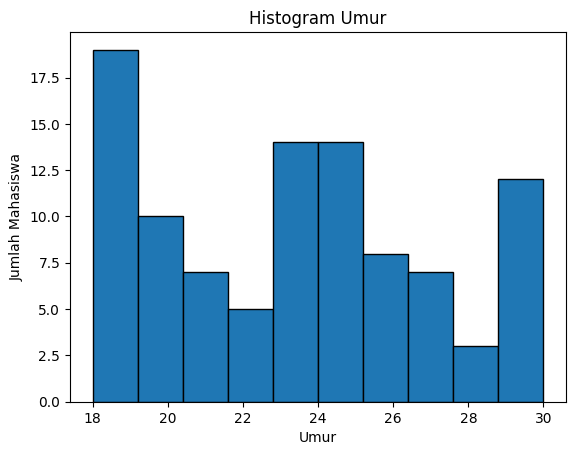

In [14]:
%matplotlib inline

df['Umur'].plot(kind='hist', bins=10, edgecolor='black')
plt.title('Histogram Umur')
plt.xlabel('Umur')
plt.ylabel('Jumlah Mahasiswa')
plt.show()

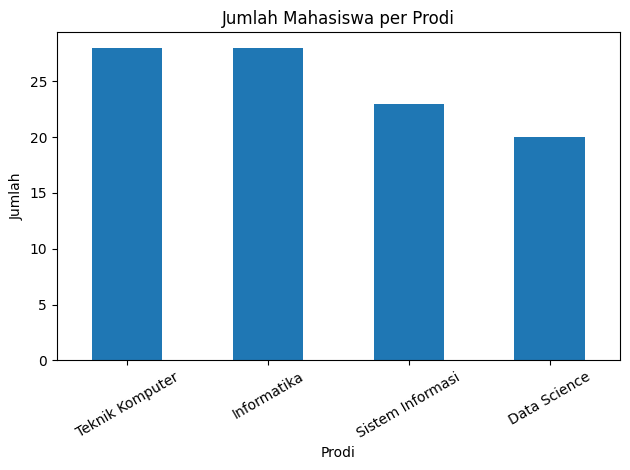

In [15]:
prodi_asli.value_counts().plot(kind='bar')
plt.title('Jumlah Mahasiswa per Prodi')
plt.xlabel('Prodi')
plt.ylabel('Jumlah')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Dari histogram, umur mahasiswa antara 18 sampai 30 tahun dan yang paling banyak di umur 23 (median, termasuk yang tadinya kosong). Di grafik batang, Teknik Komputer dan Informatika paling banyak (masing-masing 28), lalu Sistem Informasi 23 dan Data Science 20.